In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using computational device: {device}")

Using computational device: cuda


In [40]:
temp_trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
raw_data = temp_trainset.data.astype(np.float32) / 255.0
mean_stats = tuple(raw_data.mean(axis=(0, 1, 2)))
std_stats = tuple(raw_data.std(axis=(0, 1, 2)))

print(mean_stats)
print(std_stats)

(np.float32(0.4914009), np.float32(0.48215896), np.float32(0.4465308))
(np.float32(0.24703279), np.float32(0.24348423), np.float32(0.26158753))


In [63]:
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean_stats, std_stats)
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean_stats, std_stats)
])

batch_size = 128


trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
trainloader = torch.utils.data.DataLoader(
    trainset, 
    batch_size=batch_size, 
    shuffle=True, 
    drop_last=True
)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

dataiter = iter(trainloader)
images, labels = next(dataiter)

print(f"\n--- Dataset Dimensions ---")
print(f"Total training samples: {len(trainset)}")
print(f"Total test samples: {len(testset)}")
print(f"Shape of one image batch matrix: {images.shape}")
print(f"Shape of one single image tensor: {images[0].shape}")
print(f"Shape of ground-truth labels batch: {labels.shape}")


--- Dataset Dimensions ---
Total training samples: 50000
Total test samples: 10000
Shape of one image batch matrix: torch.Size([128, 3, 32, 32])
Shape of one single image tensor: torch.Size([3, 32, 32])
Shape of ground-truth labels batch: torch.Size([128])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4946066..1.5633975].



Visualizing the first 4 images from the batch:


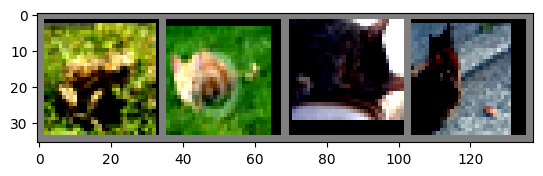

Corresponding Labels:  frog  | cat   | cat   | cat  


In [64]:
def imshow(img):
    img = img / 2 + 0.5  
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

print("\nVisualizing the first 4 images from the batch:")
imshow(torchvision.utils.make_grid(images[:4]))
print("Corresponding Labels: ", " | ".join(f"{classes[labels[j]]:5s}" for j in range(4)))

In [65]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes, planes, stride=1):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != self.expansion * planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, self.expansion * planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(self.expansion * planes)
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = torch.relu(out)
        return out

class ResNet(nn.Module):
    def __init__(self, block, num_blocks, num_classes=10):
        super(ResNet, self).__init__()
        self.in_planes = 64

        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        
        self.layer1 = self._make_layer(block, 64, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 128, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 256, num_blocks[2], stride=2)
        self.layer4 = self._make_layer(block, 512, num_blocks[3], stride=2)
        
        self.linear = nn.Linear(512 * block.expansion, num_classes)

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(block(self.in_planes, planes, s))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = nn.functional.avg_pool2d(out, 4)
        out = torch.flatten(out, 1)
        out = self.linear(out)
        return out

def ResNet18(num_classes=10):
    return ResNet(BasicBlock, [2, 2, 2, 2], num_classes)

In [66]:
def init_weights(m):
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.constant_(m.weight, 1)
        nn.init.constant_(m.bias, 0)
    elif isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, 0, 0.01)
        nn.init.constant_(m.bias, 0)

model = ResNet18(num_classes=10).to(device)
model.apply(init_weights)

loss_func = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
num_epochs = 20
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, 
    max_lr=0.1, 
    steps_per_epoch=len(trainloader), 
    epochs=num_epochs
)

In [ ]:
load_model = True
weights_path = './resnet_cifar10_weights.pth'

loss_history = []

import os
if load_model and os.path.exists(weights_path):
    print(f"\n--- Loading Pre-trained Model ---")
    print(f"Reading state_dict from {weights_path}...")
    model.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True))
    print("Model weights loaded successfully.")
else:
    print(f"\n--- Starting Network Training (ResNet-18, {num_epochs} Epochs, OneCycleLR) ---")
        
    for epoch in range(num_epochs):
        model.train() 
        running_loss = 0.0
        correct = 0
        total = 0
        
        for inputs, targets in trainloader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = loss_func(outputs, targets)
            loss.backward()
            
            optimizer.step()
            scheduler.step()
            
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
            
        epoch_loss = running_loss / len(trainloader)
        epoch_acc = 100 * correct / total
        
        current_lr = scheduler.get_last_lr()[0]
        loss_history.append(epoch_loss)
        
        if (epoch + 1) == 1 or (epoch + 1) % 5 == 0 or (epoch + 1) == num_epochs:
            print(f"Epoch [{epoch+1:3d}/{num_epochs}] | LR: {current_lr:.5f} | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.2f}%")
        
    print(f"\n--- Saving Trained Model ---")
    torch.save(model.state_dict(), weights_path)
    print(f"Model parameters successfully saved to {weights_path}")


--- Loading Pre-trained Model ---
Reading state_dict from ./resnet_cifar10_weights.pth...
Model weights loaded successfully. Bypassing training phase.


In [72]:
model.eval()
test_loss = 0.0
correct = 0
total = 0

print("\n--- Evaluating Model on Test Set ---")
with torch.no_grad():
    for inputs, targets in testloader:
        inputs, targets = inputs.to(device), targets.to(device)
        
        outputs = model(inputs)
        loss = loss_func(outputs, targets)
        test_loss += loss.item()
        
        _, predicted = torch.max(outputs.data, 1)
        total += targets.size(0)
        correct += (predicted == targets).sum().item()

final_test_loss = test_loss / len(testloader)
final_test_acc = 100 * correct / total
print(f"Final Test Loss: {final_test_loss:.4f}")
print(f"Final Test Accuracy: {final_test_acc:.2f}%")


--- Evaluating Model on Test Set ---
Final Test Loss: 0.2215
Final Test Accuracy: 92.70%


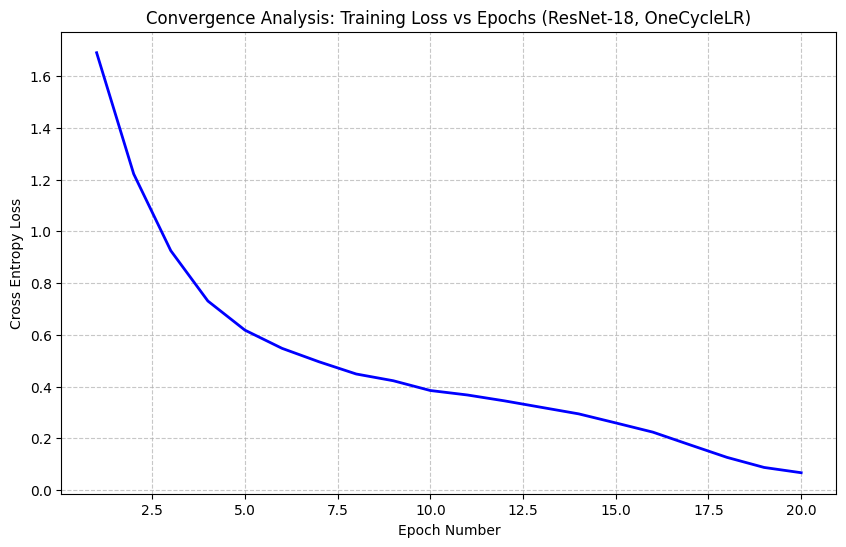

In [69]:
if not load_model:
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, num_epochs + 1), loss_history, linestyle='-', color='b', linewidth=2)
    plt.title('Convergence Analysis: Training Loss vs Epochs (ResNet-18, OneCycleLR)')
    plt.xlabel('Epoch Number')
    plt.ylabel('Cross Entropy Loss')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()